In [2]:
import pandas as pd

# Load the complete Open Air Chicago dataset
air_url = "https://data.cityofchicago.org/api/v3/views/rtmx-vkjr/export.csv"

pollution = pd.read_csv(air_url, low_memory=False)

print("Pollution dataset shape:", pollution.shape)

Pollution dataset shape: (126435, 46)


In [3]:
income = pd.read_csv(
    "../data/Chicago_Median_Income_By_Community_Area.csv"
)

print("Income dataset shape:", income.shape)

Income dataset shape: (78, 5)


In [5]:
display(income.head(10))
print(income.columns.tolist())
print(income.dtypes)

,Layer,Name,GEOID,INC_2020-2024,PCI_2020-2024
0,NaN,NaN,NaN,"Median household income, 2020-2024","Per capita income, 2020-2024"
1,Community area,Rogers Park,1.0,64982.84252006701,41401.316073557224
2,Community area,Norwood Park,10.0,117196.55685334843,53787.75290118216
3,Community area,Jefferson Park,11.0,99973.6803472109,51002.44814039693
4,Community area,Forest Glen,12.0,143029.53249393537,72837.37767535771
5,Community area,North Park,13.0,70550.56287265262,39578.42721913615
6,Community area,Albany Park,14.0,89407.95574996143,44491.796264110155
7,Community area,Portage Park,15.0,94793.33527687968,44349.38581261013
8,Community area,Irving Park,16.0,95607.64589337097,56385.870691587596
9,Community area,Dunning,17.0,90515.97830108434,44271.487412879054


['Layer', 'Name', 'GEOID', 'INC_2020-2024', 'PCI_2020-2024']
Layer             object
Name              object
GEOID            float64
INC_2020-2024     object
PCI_2020-2024     object
dtype: object


In [6]:
income_clean = income.dropna(subset=["Name"]).copy()
print("Original shape:", income.shape)
print("Cleaned shape:", income_clean.shape)

Original shape: (78, 5)
Cleaned shape: (77, 5)


In [7]:
income_clean["INC_2020-2024"] = pd.to_numeric(
    income_clean["INC_2020-2024"],
    errors="coerce"
)

print(income_clean.dtypes)

Layer             object
Name              object
GEOID            float64
INC_2020-2024    float64
PCI_2020-2024     object
dtype: object


In [8]:
print("Missing incomes:",
      income_clean["INC_2020-2024"].isna().sum())

print("Duplicate communities:",
      income_clean["Name"].duplicated().sum())

print("Unique communities:",
      income_clean["Name"].nunique())

display(income_clean["INC_2020-2024"].describe())

Missing incomes: 0
Duplicate communities: 0
Unique communities: 77


count        77.000000
mean      76728.529784
std       31573.996119
min       17398.577539
25%       55452.299643
50%       71435.726819
75%       93801.768664
max      161083.809659
Name: INC_2020-2024, dtype: float64

In [12]:
print(pollution.columns.tolist())


['datasourceid', 'outputfrequency', 'startofperiod', 'sensor_name', 'atmPressure24HourMean.raw', 'atmPressure24HourMean.value', 'bcAllSources24HourMean.raw', 'bcAllSources24HourMean.value', 'bcBiomass24HourMean.raw', 'bcBiomass24HourMean.value', 'bcFossilFuel24HourMean.raw', 'bcFossilFuel24HourMean.value', 'bcSpectralB24HourMean.raw', 'bcSpectralB24HourMean.value', 'bcSpectralG24HourMean.raw', 'bcSpectralG24HourMean.value', 'bcSpectralIR24HourMean.raw', 'bcSpectralIR24HourMean.value', 'bcSpectralR24HourMean.raw', 'bcSpectralR24HourMean.value', 'bcSpectralUV24HourMean.raw', 'bcSpectralUV24HourMean.value', 'no2Conc24HourMean.raw', 'no2Conc24HourMean.value', 'pm2_5ConcMass24HourMean.raw', 'pm2_5ConcMass24HourMean.value', 'pm2_5ConcMass24HourMeanUsEpaAqi.raw', 'pm2_5ConcMass24HourMeanUsEpaAqi.value', 'pm2_5ConcNum24HourMean.raw', 'pm2_5ConcNum24HourMean.value', 'relHumidAmbient24HourMean.raw', 'relHumidAmbient24HourMean.value', 'relHumidInternal24HourMean.raw', 'relHumidInternal24HourMean.

In [14]:
columns = [
    "sensor_name",
    "startofperiod",
    "pm2_5ConcMass24HourMean.value",
    "no2Conc24HourMean.value",
    "latitude",
    "longitude"
]

display(pollution[columns].head(10))
print("Unique sensors:", pollution["sensor_name"].nunique())

print("\nFirst 30 sensor names:")
print(pollution["sensor_name"].dropna().unique()[:30])

,sensor_name,startofperiod,pm2_5ConcMass24HourMean.value,no2Conc24HourMean.value,latitude,longitude
0,Mayfair Collocation 2,10/02/2026 12:00:00 AM,NaN,11.39,41.964742,-87.749434
1,Avalon Park 1,03/08/2026 12:00:00 AM,NaN,9.31,41.750521,-87.585793
2,Auburn Gresham 1,10/11/2025 12:00:00 AM,6.43,11.76,41.752248,-87.669190
3,Pullman 2,11/13/2025 12:00:00 AM,6.48,14.48,41.713040,-87.584305
4,Hegewisch 1,11/05/2025 12:00:00 AM,9.16,13.29,41.675190,-87.535886
5,Pullman 4,11/09/2025 12:00:00 AM,6.05,7.92,41.688426,-87.602561
6,Armour Square 2,11/05/2025 12:00:00 AM,9.58,16.03,41.840015,-87.635556
7,West Englewood 3,07/11/2026 12:00:00 AM,8.53,14.14,41.764333,-87.670135
8,Norwood Park 3,07/07/2026 12:00:00 AM,10.44,10.17,41.989852,-87.780296
9,Englewood 2,11/17/2025 12:00:00 AM,8.78,26.95,41.789576,-87.634894


Unique sensors: 286

First 30 sensor names:
['Mayfair Collocation 2' 'Avalon Park 1' 'Auburn Gresham 1' 'Pullman 2'
 'Hegewisch 1' 'Pullman 4' 'Armour Square 2' 'West Englewood 3'
 'Norwood Park 3' 'Englewood 2' 'Austin 5' 'Douglas 2' 'West Town 3'
 'Near West Side 1' 'Lincoln Park 1' 'Beverly 4' 'North Center 1'
 'Lower West Side 2' 'South Chicago 2' 'West Ridge 2' 'Irving Park 2'
 'Dunning 2' 'Belmont Cragin 4' 'Belmont Cragin 1' 'Armour Square 1'
 'Gage Park 1' 'North Park 1' 'Calumet Heights 3' 'New City 5'
 'Washington Heights 5']


In [15]:
pollution_clean = pollution.copy()

pollution_clean["community"] = (
    pollution_clean["sensor_name"]
    .str.replace(r"\s+\d+$", "", regex=True)
    .str.strip()
)

display(
    pollution_clean[["sensor_name", "community"]]
    .drop_duplicates()
    .head(20)
)

,sensor_name,community
0,Mayfair Collocation 2,Mayfair Collocation
1,Avalon Park 1,Avalon Park
2,Auburn Gresham 1,Auburn Gresham
3,Pullman 2,Pullman
4,Hegewisch 1,Hegewisch
5,Pullman 4,Pullman
6,Armour Square 2,Armour Square
7,West Englewood 3,West Englewood
8,Norwood Park 3,Norwood Park
9,Englewood 2,Englewood


In [16]:
income_names = set(
    income_clean["Name"].str.strip().str.casefold()
)

pollution_clean["community_match"] = (
    pollution_clean["community"]
    .str.casefold()
    .isin(income_names)
)

print("Matching rows:",
      pollution_clean["community_match"].sum())

print("Unmatched rows:",
      (~pollution_clean["community_match"]).sum())

print("Unmatched sensor names:")

print(
    pollution_clean.loc[
        ~pollution_clean["community_match"],
        "sensor_name"
    ].dropna().unique()
)

Matching rows: 123000
Unmatched rows: 3435
Unmatched sensor names:
['Mayfair Collocation 2' 'Washington HS Collocation 2'
 'Washington HS Collocation 3' 'Schiller Park Collocation 3'
 'Mayfair Collocation 3' 'Schiller Park Collocation 2'
 'Mayfair Collocation 1' 'Washington HS Collocation 1'
 'Schiller Park Collocation 1']


In [17]:
pollution_matched = pollution_clean[
    pollution_clean["community_match"]
].copy()

print("Matched pollution records:", len(pollution_matched))

print(
    "Communities represented:",
    pollution_matched["community"].nunique()
)

Matched pollution records: 123000
Communities represented: 77


In [18]:
income_communities = set(
    income_clean["Name"].str.casefold()
)

pollution_communities = set(
    pollution_matched["community"].str.casefold()
)

missing_communities = (
    income_communities - pollution_communities
)

print("Communities without pollution data:")
print(sorted(missing_communities))

Communities without pollution data:
[]


In [20]:
pollutants = [
    "pm2_5ConcMass24HourMean.value",
    "no2Conc24HourMean.value"
]

for column in pollutants:
    pollution_matched[column] = pd.to_numeric(
        pollution_matched[column],
        errors="coerce"
    )

print("Missing pollution measurements:")

print(
    pollution_matched[pollutants].isna().sum()
)

print("\nPollution summary statistics:")

display(
    pollution_matched[pollutants].describe()
)

Missing pollution measurements:
pm2_5ConcMass24HourMean.value    1341
no2Conc24HourMean.value           379
dtype: int64

Pollution summary statistics:


,pm2_5ConcMass24HourMean.value,no2Conc24HourMean.value
count,121659.000000,122621.000000
mean,10.786647,15.281147
std,11.059823,4.527137
min,1.690000,2.340000
25%,6.240000,12.150000
50%,8.880000,14.500000
75%,12.640000,17.520000
max,279.190000,53.630000


In [24]:
display(
    pollution_matched.nlargest(
        10, "pm2_5ConcMass24HourMean.value"
    )[
        [
            "sensor_name",
            "startofperiod",
            "pm2_5ConcMass24HourMean.value",
            "no2Conc24HourMean.value"
        ]
    ]
)
pollution_matched["date"] = pd.to_datetime(
    pollution_matched["startofperiod"],
    errors="coerce",
    utc=True
)

print("Earliest date:", pollution_matched["date"].min())
print("Latest date:", pollution_matched["date"].max())
print("Missing dates:", pollution_matched["date"].isna().sum())

,sensor_name,startofperiod,pm2_5ConcMass24HourMean.value,no2Conc24HourMean.value
53595,West Ridge 4,07/16/2026 12:00:00 AM,279.19,15.20
51737,Lincoln Square 1,07/17/2026 12:00:00 AM,231.28,12.54
50240,Norwood Park 2,07/17/2026 12:00:00 AM,218.69,16.00
51278,Armour Square 2,07/17/2026 12:00:00 AM,216.81,13.88
47477,South Deering 6,07/17/2026 12:00:00 AM,210.48,12.54
49166,North Lawndale 5,07/17/2026 12:00:00 AM,209.38,18.43
48289,Hegewisch 5,07/17/2026 12:00:00 AM,208.92,15.36
56388,North Lawndale 3,07/17/2026 12:00:00 AM,208.15,12.98
57333,Pullman 4,07/17/2026 12:00:00 AM,205.46,11.71
50157,Calumet Heights 3,07/17/2026 12:00:00 AM,204.67,12.06


Earliest date: 2025-07-26 00:00:00+00:00
Latest date: 2026-11-12 00:00:00+00:00
Missing dates: 0


/tmp/ipykernel_79487/599343251.py:13: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pollution_matched["date"] = pd.to_datetime(


In [25]:
sensor_counts = (
    pollution_matched.groupby("community")["sensor_name"]
    .nunique()
    .sort_values()
)

display(sensor_counts.describe())

print("Communities with fewest sensors:")
display(sensor_counts.head(10))

count    77.000000
mean      3.597403
std       1.879668
min       1.000000
25%       2.000000
50%       3.000000
75%       5.000000
max      10.000000
Name: sensor_name, dtype: float64

Communities with fewest sensors:


community
West Garfield Park    1
Fuller Park           1
Washington Park       1
Oakland               1
North Center          1
Kenwood               1
Burnside              1
Lincoln Park          2
Grand Boulevard       2
Hermosa               2
Name: sensor_name, dtype: int64

In [28]:
sensor_summary = (
    pollution_matched
    .groupby(["community", "sensor_name"])
    .agg(
        avg_pm25=("pm2_5ConcMass24HourMean.value", "mean"),
        avg_no2=("no2Conc24HourMean.value", "mean"),
        pm25_count=("pm2_5ConcMass24HourMean.value", "count"),
        no2_count=("no2Conc24HourMean.value", "count"),
        days_reported=("date", "nunique"),
        max_pm25=("pm2_5ConcMass24HourMean.value", "max")
    )
    .reset_index()
)

display(sensor_summary.head(10))
print("Number of sensors:", len(sensor_summary))

display(sensor_summary["days_reported"].describe())

print("Sensors with fewest reporting days:")
display(
    sensor_summary.nsmallest(10, "days_reported")
)

,community,sensor_name,avg_pm25,avg_no2,pm25_count,no2_count,days_reported,max_pm25
0,Albany Park,Albany Park 1,10.900594,15.603630,438,438,438,161.08
1,Albany Park,Albany Park 2,11.553593,14.126525,423,423,423,170.73
2,Albany Park,Albany Park 3,11.297123,13.730114,438,437,438,163.72
3,Archer Heights,Archer Heights 1,11.136636,19.936165,434,425,434,171.77
4,Archer Heights,Archer Heights 2,10.277735,17.170989,437,445,446,166.64
5,Archer Heights,Archer Heights 3,11.544439,17.740874,446,446,446,159.87
6,Archer Heights,Archer Heights 4,9.397910,14.155404,445,446,446,156.68
7,Armour Square,Armour Square 1,11.232671,14.676490,453,453,453,194.75
8,Armour Square,Armour Square 2,11.246777,17.437108,453,453,453,216.81
9,Armour Square,Armour Square 3,10.976831,15.026225,445,445,445,186.85


Number of sensors: 277


count    277.000000
mean     444.043321
std       36.409879
min      139.000000
25%      438.000000
50%      449.000000
75%      460.000000
max      474.000000
Name: days_reported, dtype: float64

Sensors with fewest reporting days:


,community,sensor_name,avg_pm25,avg_no2,pm25_count,no2_count,days_reported,max_pm25
234,South Lawndale,South Lawndale 4,9.467536,18.420455,138,132,139,26.56
144,Loop,Loop 1,10.950250,17.706550,200,200,200,161.67
222,South Deering,South Deering 10,9.127744,14.992717,195,184,201,29.00
230,South Deering,South Deering 9,9.696863,15.892513,204,191,204,25.72
240,Uptown,Uptown 2,10.570741,15.486728,324,324,324,178.48
163,Near North Side,Near North Side 4,11.470241,15.587868,332,333,333,168.45
228,South Deering,South Deering 7,11.058265,16.351326,340,377,377,123.63
115,Humboldt Park,Humboldt Park 2,11.534974,15.049524,378,378,378,167.07
120,Hyde Park,Hyde Park 2,9.787816,12.230449,380,379,380,158.34
258,West Lawn,West Lawn 4,10.716590,18.595573,393,393,393,135.16


In [32]:
community_summary = (
    sensor_summary
    .groupby("community")
    .agg(
        avg_pm25=("avg_pm25", "mean"),
        avg_no2=("avg_no2", "mean"),
        sensor_count=("sensor_name", "nunique")
    )
    .reset_index()
)

print("Shape:", community_summary.shape)

display(community_summary.head(10))

Shape: (77, 4)


,community,avg_pm25,avg_no2,sensor_count
0,Albany Park,11.250437,14.486756,3
1,Archer Heights,10.589180,17.250858,4
2,Armour Square,11.152093,15.713274,3
3,Ashburn,10.613229,14.719459,8
4,Auburn Gresham,10.730595,14.667922,5
5,Austin,11.021248,15.470884,9
6,Avalon Park,13.061145,13.842519,3
7,Avondale,10.498967,15.513873,2
8,Belmont Cragin,10.805167,15.485394,4
9,Beverly,10.096490,13.700739,5


In [33]:
income_for_merge = income_clean[
    ["Name", "INC_2020-2024"]
].copy()

income_for_merge = income_for_merge.rename(
    columns={
        "Name": "community",
        "INC_2020-2024": "median_income"
    }
)

display(income_for_merge.head())

,community,median_income
1,Rogers Park,64982.842520
2,Norwood Park,117196.556853
3,Jefferson Park,99973.680347
4,Forest Glen,143029.532494
5,North Park,70550.562873


In [30]:
display(
    pollution_matched.nlargest(
        10, "pm2_5ConcMass24HourMean.value"
    )[[
        "sensor_name",
        "community",
        "date",
        "pm2_5ConcMass24HourMean.value"
    ]]
)

,sensor_name,community,date,pm2_5ConcMass24HourMean.value
53595,West Ridge 4,West Ridge,2026-07-16 00:00:00+00:00,279.19
51737,Lincoln Square 1,Lincoln Square,2026-07-17 00:00:00+00:00,231.28
50240,Norwood Park 2,Norwood Park,2026-07-17 00:00:00+00:00,218.69
51278,Armour Square 2,Armour Square,2026-07-17 00:00:00+00:00,216.81
47477,South Deering 6,South Deering,2026-07-17 00:00:00+00:00,210.48
49166,North Lawndale 5,North Lawndale,2026-07-17 00:00:00+00:00,209.38
48289,Hegewisch 5,Hegewisch,2026-07-17 00:00:00+00:00,208.92
56388,North Lawndale 3,North Lawndale,2026-07-17 00:00:00+00:00,208.15
57333,Pullman 4,Pullman,2026-07-17 00:00:00+00:00,205.46
50157,Calumet Heights 3,Calumet Heights,2026-07-17 00:00:00+00:00,204.67


In [31]:
daily_pm25 = (
    pollution_matched
    .groupby("date")
    .agg(
        avg_pm25=("pm2_5ConcMass24HourMean.value", "mean"),
        median_pm25=("pm2_5ConcMass24HourMean.value", "median")
    )
    .reset_index()
)

display(
    daily_pm25[
        daily_pm25["date"].dt.strftime("%Y-%m-%d")
        .between("2026-07-15", "2026-07-20")
    ]
)

,date,avg_pm25,median_pm25
354,2026-07-15 00:00:00+00:00,12.544834,12.630
355,2026-07-16 00:00:00+00:00,133.537143,134.590
356,2026-07-17 00:00:00+00:00,168.139118,166.970
357,2026-07-18 00:00:00+00:00,13.078022,13.125
358,2026-07-19 00:00:00+00:00,43.252639,43.690
359,2026-07-20 00:00:00+00:00,35.596543,35.900


In [35]:
income_for_merge = income_clean[
    ["Name", "INC_2020-2024"]
].copy()

income_for_merge = income_for_merge.rename(
    columns={
        "Name": "community",
        "INC_2020-2024": "median_income"
    }
)

display(income_for_merge.head())

,community,median_income
1,Rogers Park,64982.842520
2,Norwood Park,117196.556853
3,Jefferson Park,99973.680347
4,Forest Glen,143029.532494
5,North Park,70550.562873


In [37]:
income_for_merge["community"] = (
    income_for_merge["community"].str.strip().str.casefold()
)

community_for_merge = community_summary.copy()

community_for_merge["community"] = (
    community_for_merge["community"].str.strip().str.casefold()
)

model_data = community_for_merge.merge(
    income_for_merge,
    on="community",
    how="left",
    validate="one_to_one",
    indicator=True
)

In [38]:
print("Shape:", model_data.shape)

print("\nMerge results:")
print(model_data["_merge"].value_counts())

print("\nMissing values:")
print(
    model_data[
        ["median_income", "avg_pm25", "avg_no2"]
    ].isna().sum()
)

display(model_data.head(10))

Shape: (77, 6)

Merge results:
_merge
both          77
left_only      0
right_only     0
Name: count, dtype: int64

Missing values:
median_income    0
avg_pm25         0
avg_no2          0
dtype: int64


,community,avg_pm25,avg_no2,sensor_count,median_income,_merge
0,albany park,11.250437,14.486756,3,89407.955750,both
1,archer heights,10.589180,17.250858,4,68913.018652,both
2,armour square,11.152093,15.713274,3,46869.983533,both
3,ashburn,10.613229,14.719459,8,86172.611560,both
4,auburn gresham,10.730595,14.667922,5,49585.997282,both
5,austin,11.021248,15.470884,9,53210.220205,both
6,avalon park,13.061145,13.842519,3,62163.981586,both
7,avondale,10.498967,15.513873,2,94420.991895,both
8,belmont cragin,10.805167,15.485394,4,71804.049116,both
9,beverly,10.096490,13.700739,5,134420.316495,both


In [41]:
from scipy.stats import pearsonr, spearmanr

for pollutant in ["avg_pm25", "avg_no2"]:
    pearson = pearsonr(
        model_data["median_income"],
        model_data[pollutant]
    )

    spearman = spearmanr(
        model_data["median_income"],
        model_data[pollutant]
    )

    print(f"\n{pollutant}")
    print(f"Pearson r: {pearson.statistic:.4f}")
    print(f"Pearson p-value: {pearson.pvalue:.4f}")
    print(f"Spearman rho: {spearman.statistic:.4f}")
    print(f"Spearman p-value: {spearman.pvalue:.4f}")
    result = pearsonr(
    model_data["median_income"],
    model_data["avg_pm25"]
)

ci = result.confidence_interval(confidence_level=0.95)

print("PM2.5 Pearson correlation:", result.statistic)
print("95% confidence interval:", ci)


avg_pm25
Pearson r: -0.1195
Pearson p-value: 0.3007
Spearman rho: -0.0741
Spearman p-value: 0.5217

avg_no2
Pearson r: -0.0428
Pearson p-value: 0.7114
Spearman rho: -0.0236
Spearman p-value: 0.8383
PM2.5 Pearson correlation: -0.11946695716881042
95% confidence interval: ConfidenceInterval(low=-0.33449533952895116, high=0.10738529800940422)


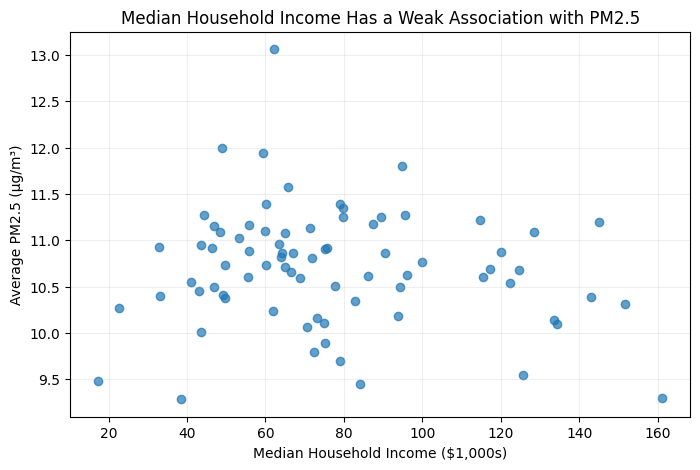

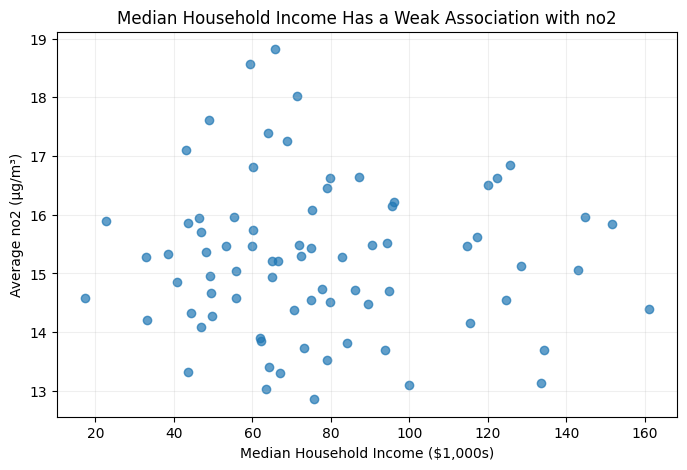

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    model_data["median_income"] / 1000,
    model_data["avg_pm25"],
    alpha=0.7
)

plt.xlabel("Median Household Income ($1,000s)")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.title("Median Household Income Has a Weak Association with PM2.5")

plt.grid(alpha=0.2)
plt.show()


plt.figure(figsize=(8, 5))

plt.scatter(
    model_data["median_income"] / 1000,
    model_data["avg_no2"],
    alpha=0.7
)

plt.xlabel("Median Household Income ($1,000s)")
plt.ylabel("Average no2 (µg/m³)")
plt.title("Median Household Income Has a Weak Association with no2")

plt.grid(alpha=0.2)
plt.show()

Testing with models


In [46]:
from sklearn.model_selection import train_test_split

# X is our predictor (median household income)
X = model_data[["median_income"]]

# y is what we want to predict (average PM2.5)
y = model_data["avg_pm25"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training communities:", len(X_train))
print("Testing communities:", len(X_test))

Training communities: 61
Testing communities: 16


In [47]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Baseline RMSE:", baseline_rmse)

Baseline RMSE: 0.677337730602308


In [48]:
from sklearn.linear_model import LinearRegression

income_model = LinearRegression()

income_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [49]:
income_predictions = income_model.predict(X_test)

print("First 5 predictions:")
print(income_predictions[:5])

print("\nFirst 5 actual values:")
print(y_test.iloc[:5].values)

First 5 predictions:
[10.83158838 10.65495779 10.72550023 10.69199522 10.74289286]

First 5 actual values:
[10.73059499 10.76568575 11.25244712 11.25043676 10.10844752]


In [50]:
income_rmse = np.sqrt(
    mean_squared_error(y_test, income_predictions)
)

print("Baseline RMSE:", baseline_rmse)
print("Income model RMSE:", income_rmse)
print("Difference:", baseline_rmse - income_rmse)

Baseline RMSE: 0.677337730602308
Income model RMSE: 0.7003358850558915
Difference: -0.022998154453583552


In [54]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_cv = cross_val_score(
    DummyRegressor(strategy="mean"),
    X,
    y,
    cv=cv,
    scoring="neg_mean_squared_error"
)

baseline_cv_rmse = np.sqrt(-baseline_cv)

print("Baseline RMSE for each fold:")
print(baseline_cv_rmse)

print("Mean baseline RMSE:", baseline_cv_rmse.mean())
print("Standard deviation:", baseline_cv_rmse.std())



income_cv = cross_val_score(
    LinearRegression(),
    X,
    y,
    cv=cv,
    scoring="neg_mean_squared_error"
)

income_cv_rmse = np.sqrt(-income_cv)

print("Income model RMSE for each fold:")
print(income_cv_rmse)

print("Mean income RMSE:", income_cv_rmse.mean())
print("Standard deviation:", income_cv_rmse.std())

print(
    "Mean baseline RMSE:",
    baseline_cv_rmse.mean()
)

print(
    "Mean income RMSE:",
    income_cv_rmse.mean()
)

print(
    "RMSE improvement:",
    baseline_cv_rmse.mean() - income_cv_rmse.mean()
)

Baseline RMSE for each fold:
[0.67733773 0.42954117 0.8688278  0.57386414 0.53834817]
Mean baseline RMSE: 0.6175838028022678
Standard deviation: 0.14848825233450924
Income model RMSE for each fold:
[0.70033589 0.41548988 0.85986228 0.57669979 0.53677859]
Mean income RMSE: 0.6178332847531818
Standard deviation: 0.15138652265131453
Mean baseline RMSE: 0.6175838028022678
Mean income RMSE: 0.6178332847531818
RMSE improvement: -0.00024948195091401004


In [56]:
y_no2 = model_data["avg_no2"]
no2_baseline_scores = cross_val_score(
    DummyRegressor(strategy="mean"),
    X,
    y_no2,
    cv=cv,
    scoring="neg_mean_squared_error"
)

no2_baseline_rmse = np.sqrt(-no2_baseline_scores)

print("NO2 Baseline RMSE:", no2_baseline_rmse)
print("Mean:", no2_baseline_rmse.mean())
print("Standard deviation:", no2_baseline_rmse.std())

NO2 Baseline RMSE: [1.33402697 1.10838185 1.4104876  1.75863338 0.96513527]
Mean: 1.3153330151015485
Standard deviation: 0.27253855367930313


In [58]:
no2_income_scores = cross_val_score(
    LinearRegression(),
    X,
    y_no2,
    cv=cv,
    scoring="neg_mean_squared_error"
)

no2_income_rmse = np.sqrt(-no2_income_scores)

print("NO2 Income RMSE:", no2_income_rmse)
print("Mean:", no2_income_rmse.mean())
print("Standard deviation:", no2_income_rmse.std())
improvement = (
    no2_baseline_rmse.mean()
    - no2_income_rmse.mean()
)

print("NO2 RMSE improvement:", improvement)

NO2 Income RMSE: [1.33157194 1.10506445 1.40941351 1.81365058 0.96557784]
Mean: 1.3250556645016178
Standard deviation: 0.2910340682197081
NO2 RMSE improvement: -0.009722649400069283


In [59]:
smoke_dates = ["2026-07-16", "2026-07-17"]

pollution_no_smoke = pollution_matched[
    ~pollution_matched["date"]
    .dt.strftime("%Y-%m-%d")
    .isin(smoke_dates)
].copy()

print("Original records:", len(pollution_matched))
print("Records without smoke dates:", len(pollution_no_smoke))
print(
    "Records removed:",
    len(pollution_matched) - len(pollution_no_smoke)
)

Original records: 123000
Records without smoke dates: 122452
Records removed: 548


In [61]:
print(
    pollution_no_smoke["date"]
    .dt.strftime("%Y-%m-%d")
    .isin(smoke_dates)
    .sum()
)

print(
    "Communities remaining:",
    pollution_no_smoke["community"].nunique()
)

0
Communities remaining: 77


In [62]:
sensor_no_smoke = (
    pollution_no_smoke
    .groupby(["community", "sensor_name"])
    .agg(
        avg_pm25=("pm2_5ConcMass24HourMean.value", "mean"),
        avg_no2=("no2Conc24HourMean.value", "mean")
    )
    .reset_index()
)

print("Sensors remaining:", len(sensor_no_smoke))
display(sensor_no_smoke.head())

Sensors remaining: 277


,community,sensor_name,avg_pm25,avg_no2
0,Albany Park,Albany Park 1,10.246583,15.611858
1,Albany Park,Albany Park 2,10.822922,14.130404
2,Albany Park,Albany Park 3,10.633876,13.730575
3,Archer Heights,Archer Heights 1,10.518356,19.947612
4,Archer Heights,Archer Heights 2,9.681724,17.170519


In [63]:
community_no_smoke = (
    sensor_no_smoke
    .groupby("community")
    .agg(
        avg_pm25=("avg_pm25", "mean"),
        avg_no2=("avg_no2", "mean")
    )
    .reset_index()
)

print("Communities:", len(community_no_smoke))
display(community_no_smoke.head())

Communities: 77


,community,avg_pm25,avg_no2
0,Albany Park,10.567793,14.490945
1,Archer Heights,10.001340,17.256228
2,Armour Square,10.406097,15.714315
3,Ashburn,10.039897,14.716916
4,Auburn Gresham,10.157849,14.671020


In [64]:
comparison = community_summary.merge(
    community_no_smoke,
    on="community",
    suffixes=("_original", "_no_smoke")
)

comparison["pm25_difference"] = (
    comparison["avg_pm25_original"]
    - comparison["avg_pm25_no_smoke"]
)

display(
    comparison[
        ["community", "avg_pm25_original",
         "avg_pm25_no_smoke", "pm25_difference"]
    ].head(10)
)

print("Average change across communities:",
      comparison["pm25_difference"].mean())

,community,avg_pm25_original,avg_pm25_no_smoke,pm25_difference
0,Albany Park,11.250437,10.567793,0.682643
1,Archer Heights,10.589180,10.001340,0.587840
2,Armour Square,11.152093,10.406097,0.745996
3,Ashburn,10.613229,10.039897,0.573332
4,Auburn Gresham,10.730595,10.157849,0.572746
5,Austin,11.021248,10.408063,0.613185
6,Avalon Park,13.061145,12.305093,0.756052
7,Avondale,10.498967,9.884612,0.614355
8,Belmont Cragin,10.805167,10.177587,0.627580
9,Beverly,10.096490,9.640266,0.456224


Average change across communities: 0.6337558859175544


In [65]:
no_smoke_model = model_data[
    ["community", "median_income"]
].merge(
    community_no_smoke.assign(
        community=community_no_smoke["community"].str.strip().str.casefold()
    ),
    on="community",
    how="left",
    validate="one_to_one"
)

print("Shape:", no_smoke_model.shape)
print("Missing values:")
print(no_smoke_model.isna().sum())

display(no_smoke_model.head())


Shape: (77, 4)
Missing values:
community        0
median_income    0
avg_pm25         0
avg_no2          0
dtype: int64


,community,median_income,avg_pm25,avg_no2
0,albany park,89407.955750,10.567793,14.490945
1,archer heights,68913.018652,10.001340,17.256228
2,armour square,46869.983533,10.406097,15.714315
3,ashburn,86172.611560,10.039897,14.716916
4,auburn gresham,49585.997282,10.157849,14.671020


In [66]:
X_no_smoke = no_smoke_model[["median_income"]]
y_no_smoke = no_smoke_model["avg_pm25"]

baseline_no_smoke_scores = cross_val_score(
    DummyRegressor(strategy="mean"),
    X_no_smoke,
    y_no_smoke,
    cv=cv,
    scoring="neg_mean_squared_error"
)

baseline_no_smoke_rmse = np.sqrt(
    -baseline_no_smoke_scores
)

print("Baseline RMSE by fold:", baseline_no_smoke_rmse)
print("Mean baseline RMSE:", baseline_no_smoke_rmse.mean())

Baseline RMSE by fold: [0.65345568 0.39381825 0.83450678 0.57216526 0.47275836]
Mean baseline RMSE: 0.5853408666563429


In [67]:
income_no_smoke_scores = cross_val_score(
    LinearRegression(),
    X_no_smoke,
    y_no_smoke,
    cv=cv,
    scoring="neg_mean_squared_error"
)

income_no_smoke_rmse = np.sqrt(
    -income_no_smoke_scores
)

print("Income model RMSE by fold:", income_no_smoke_rmse)
print("Mean income RMSE:", income_no_smoke_rmse.mean())

Income model RMSE by fold: [0.67672562 0.3814172  0.82296699 0.568366   0.46741261]
Mean income RMSE: 0.5833776835329813


In [68]:
improvement_no_smoke = (
    baseline_no_smoke_rmse.mean()
    - income_no_smoke_rmse.mean()
)

print("Original improvement:",
      baseline_cv_rmse.mean() - income_cv_rmse.mean())

print("Improvement without July 16–17:",
      improvement_no_smoke)

Original improvement: -0.00024948195091401004
Improvement without July 16–17: 0.0019631831233616337


In [70]:
cv_comparison = pd.DataFrame({
    "fold": range(1, 6),
    "original_baseline": baseline_cv_rmse,
    "original_income": income_cv_rmse,
    "filtered_baseline": baseline_no_smoke_rmse,
    "filtered_income": income_no_smoke_rmse
})

cv_comparison["original_improvement"] = (
    cv_comparison["original_baseline"]
    - cv_comparison["original_income"]
)

cv_comparison["filtered_improvement"] = (
    cv_comparison["filtered_baseline"]
    - cv_comparison["filtered_income"]
)

display(cv_comparison)
print("Original improvement:")
print(cv_comparison["original_improvement"].describe())

print("\nWithout July 16–17:")
print(cv_comparison["filtered_improvement"].describe())

,fold,original_baseline,original_income,filtered_baseline,filtered_income,original_improvement,filtered_improvement
0,1,0.677338,0.700336,0.653456,0.676726,-0.022998,-0.023270
1,2,0.429541,0.415490,0.393818,0.381417,0.014051,0.012401
2,3,0.868828,0.859862,0.834507,0.822967,0.008966,0.011540
3,4,0.573864,0.576700,0.572165,0.568366,-0.002836,0.003799
4,5,0.538348,0.536779,0.472758,0.467413,0.001570,0.005346


Original improvement:
count    5.000000
mean    -0.000249
std      0.014291
min     -0.022998
25%     -0.002836
50%      0.001570
75%      0.008966
max      0.014051
Name: original_improvement, dtype: float64

Without July 16–17:
count    5.000000
mean     0.001963
std      0.014596
min     -0.023270
25%      0.003799
50%      0.005346
75%      0.011540
max      0.012401
Name: filtered_improvement, dtype: float64


In [72]:
threshold = model_data["avg_pm25"].quantile(0.75)

print("75th-percentile PM2.5:", threshold)

model_data["high_pm25"] = (
    model_data["avg_pm25"] >= threshold
).astype(int)

print(model_data["high_pm25"].value_counts())

display(
    model_data.loc[
        model_data["high_pm25"] == 1,
        ["community", "median_income", "avg_pm25"]
    ].sort_values("avg_pm25", ascending=False)
)

75th-percentile PM2.5: 11.093671171171172
high_pm25
0    57
1    20
Name: count, dtype: int64


,community,median_income,avg_pm25
6,avalon park,62163.981586,13.061145
52,north lawndale,48940.463732,11.997451
50,new city,59344.984477,11.944618
57,portage park,94793.335277,11.796657
11,brighton park,65766.349587,11.573984
64,south lawndale,60232.002443,11.396292
42,lower west side,79001.655695,11.394427
69,west elsdon,79826.911808,11.353175
34,irving park,95607.645893,11.274759
71,west garfield park,44427.692980,11.269876


In [74]:
income_by_pollution = (
    model_data
    .groupby("high_pm25")["median_income"]
    .agg(["count", "mean", "median", "std"])
)

display(income_by_pollution)

income_difference = (
    income_by_pollution.loc[1, "median"]
    - income_by_pollution.loc[0, "median"]
)

print("Median income difference:", income_difference)

,count,mean,median,std
high_pm25,,,,
0,57,77531.616083,71804.049116,33669.039079
1,20,74439.733832,68601.038203,25279.845331


Median income difference: -3203.0109135800303


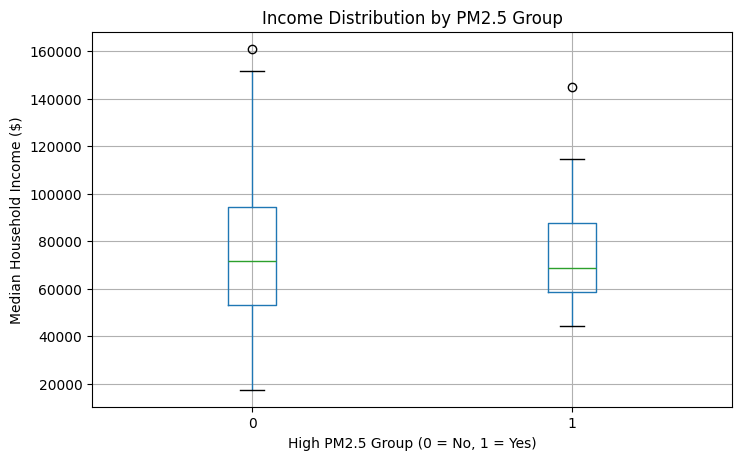

In [75]:
import matplotlib.pyplot as plt

model_data.boxplot(
    column="median_income",
    by="high_pm25",
    figsize=(8, 5)
)

plt.xlabel("High PM2.5 Group (0 = No, 1 = Yes)")
plt.ylabel("Median Household Income ($)")
plt.title("Income Distribution by PM2.5 Group")
plt.suptitle("")
plt.show()

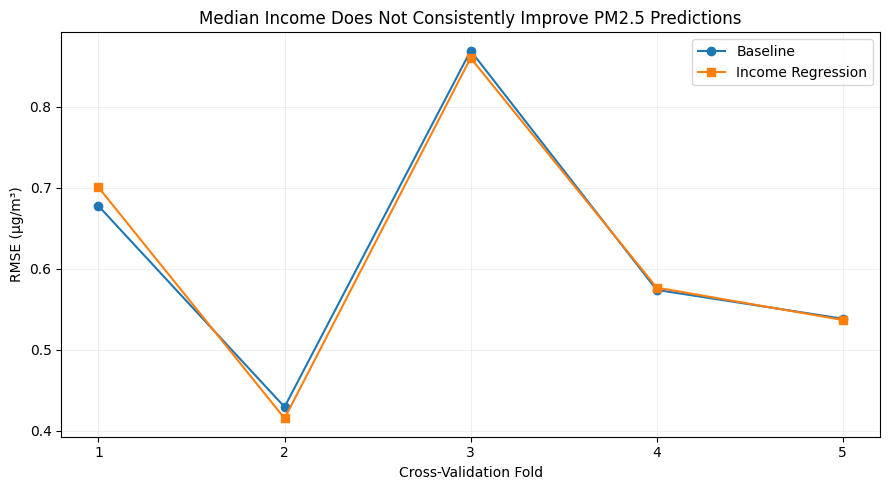

In [76]:
import matplotlib.pyplot as plt

folds = range(1, 6)

plt.figure(figsize=(9, 5))

plt.plot(
    folds,
    baseline_cv_rmse,
    marker="o",
    label="Baseline"
)

plt.plot(
    folds,
    income_cv_rmse,
    marker="s",
    label="Income Regression"
)

plt.xlabel("Cross-Validation Fold")
plt.ylabel("RMSE (µg/m³)")
plt.title(
    "Median Income Does Not Consistently Improve PM2.5 Predictions"
)

plt.xticks(list(folds))
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()